# Model 3 – Fine tuned pre-trained model 

<h2>1. Business understanding</h2>
  
This notebook contains the fine-tuned pre-trained model with frozen lower layers and adapted upper layers. The comparison between this model and the previous model (VGG16 model with feature extraction) is done in a separate notebook. The purpose of this model is to classify images into one of three classes: rock, paper or scissors. 

<h2>2. Data understanding</h2>

The dataset consists of our own images of hands showing the three rock-paper-scissors gestures: rock, paper, and scissors.

In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import numpy as np

import keras
from keras import layers
from keras.utils import image_dataset_from_directory, set_random_seed
from keras.regularizers import l2

# set random seed to make the model training results reproducible
set_random_seed(42)

# directory with all data
rps_dir = pathlib.Path("./rps") 

The random seed is set to 42 to make the results reproducible. Without a seed, two runs of the same model gave different results (validation accuracy 0.81 vs. 0.77). The results are reproducible when the whole notebook is run from top to bottom. Because of the small validation set, small differences between models may still occur. 

<h2>3. Data preparation</h2>

Let's upload the images from directory.

In [2]:
# SUPPORTS FORMATS: JPEG (.jpg, .jpeg), PNG (.png), BMP (.bmp) AND GIF (.gif)

train_dataset = image_dataset_from_directory(
    rps_dir / "train",
    image_size = (180, 180),
    batch_size = 32)

validation_dataset = image_dataset_from_directory(
    rps_dir / "validation",
    image_size = (180, 180),
    batch_size = 32)

test_dataset = image_dataset_from_directory(
    rps_dir / "test",
    image_size = (180, 180),
    batch_size = 32,
    shuffle = False) # no shuffling to test data

Found 191 files belonging to 3 classes.
Found 53 files belonging to 3 classes.
Found 53 files belonging to 3 classes.


The dataset contains 191 training images, 53 validation images and 53 test images, total 297. The test data is not shuffled. This keeps the images in a fixed order, so that the predictions, true labels and file paths match each other when we make the confusion matrix and look at misclassified images.

Let's print the class labels.

In [3]:
print(train_dataset.class_names)

# the labels of one batch (32 images)
for images, labels in train_dataset.take(1):
    print(labels.numpy())

['paper', 'rock', 'scissors']
[2 1 1 0 1 2 0 1 2 0 0 1 2 2 0 2 1 1 0 2 1 2 2 2 1 2 1 2 0 2 1 2]


We can see that Keras has shuffled the dataset while loading the images, ensuring that the models are trained on images from each class.  

The indices are as follows:   
- 0 = paper  
- 1 = rock  
- 2 = scissors

<h2>4. Modeling</h2>

Let's use the VGG16 model as a base. The convolutional layers are locked, and our own model is added on top (upper layers are adapted). That means, the VGG16 works as a base, and the additional model (upper layers) are trained with our rock-paper-scissors dataset. In other words, the VGG16 model's weights are not updated during the training. The model uses ImageNet data, from which it has learned all the weights it has already.  

`include_top=False` excludes the original upper layer of the VGG16 model.

In [4]:
# VGG16 model with freezed layers, upper layer excluded
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)
conv_base.trainable = False

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

The VGG16 model has 19 layers with 14,714,688 total parameters. All of these are non-trainable because of the freezing we made with `conv_base.trainable = False`.   

Let's use data augmentation to provide different versions of the images to the model during training. In each epoch, the images are getting random transformations. This might help the model classify new images instead of memorizing the training images.

In [5]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2)
    ]
)

Next, we try different models to find the best-performing one in terms of validation accuracy. We use validation loss (val_loss) to save the best model during training and compare the models based on their validation accuracy.

### Model 1

The first model has one hidden layer with 256 neurons with `ReLU` activation. 50% of the samples are randomly discarded with dropout. The output layer uses `softmax` activation function, which gives propabilities for each of the tree classes. We compile the model with `sparse_categorical_crossentropy` loss function, which accepts integer class labels instead of one-hot-encoded labels. Our class labels are 0, 1 and 2. The optimizer is `rmsprop`.

In [6]:
inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(3, activation="softmax")(x)

model_01 = keras.Model(inputs, outputs)

model_01.compile(loss="sparse_categorical_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

model_01.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 180, 180,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 180, 180)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 180, 180)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 180, 180)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 180, 180,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 180, 180,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 5, 5, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 12800)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  3,277,056 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        771 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,992,515 (68.64 MB)

 Trainable params: 3,277,827 (12.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

This model has 3,277,827 trainable parameters.  

Next, we train the model for 50 epochs. `callbacks_01` saves the best-performing model (with best weights) during training, based on the validation loss. The model is saved into a separate file named `01_fine_tuned_VGG16.keras`. The `history_01` object stores the training and validation metrics from each epoch. 

In [7]:
callbacks_01 = [
    keras.callbacks.ModelCheckpoint(
        filepath="./model3_checkpoints/01_fine_tuned_VGG16.keras",
        save_best_only=True,
        monitor="val_loss")
]

history_01 = model_01.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks_01,
    verbose=0
)

C:\Users\OWNER\anaconda3\envs\tensorflow\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Let's print the validation metrics, and plot the graphs.

Best epoch: 21
Training accuracy: 0.9581
Validation accuracy: 0.7358
Training loss: 0.2419
Validation loss: 2.3668


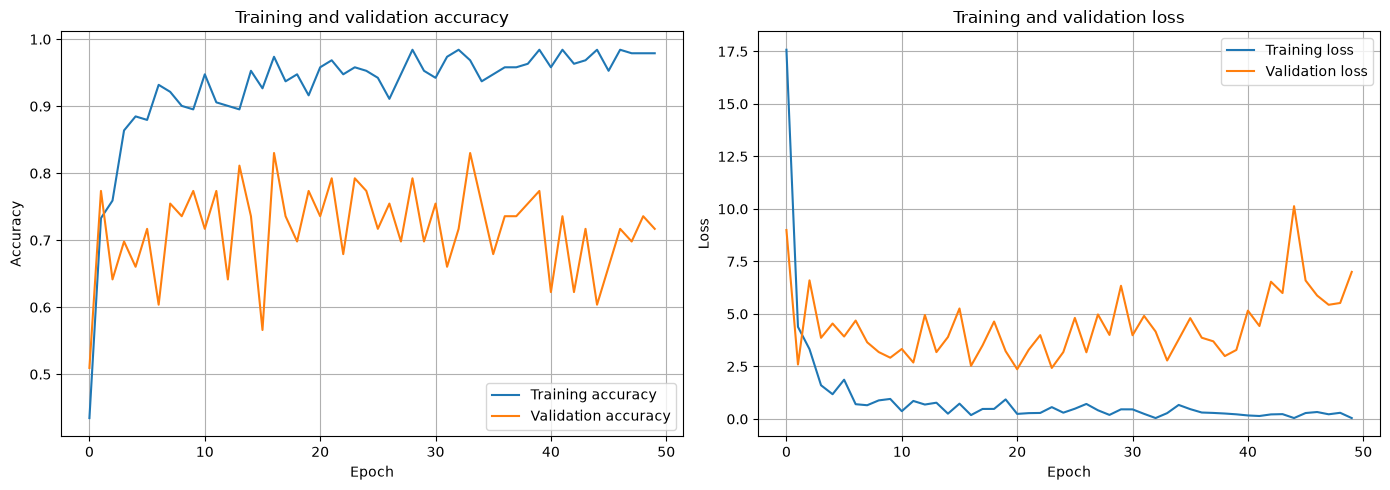

In [8]:
# print best epoch results
def display_validation_results(history):
    
    # find the best epoch based on validation loss
    best_epoch = np.argmin(history.history['val_loss'])
    
    print(f"Best epoch: {best_epoch + 1}")
    print(f"Training accuracy: {history.history['accuracy'][best_epoch]:.4f}")
    print(f"Validation accuracy: {history.history['val_accuracy'][best_epoch]:.4f}")
    print(f"Training loss: {history.history['loss'][best_epoch]:.4f}")
    print(f"Validation loss: {history.history['val_loss'][best_epoch]:.4f}")

def plot_training_history(history):
    # get values from history
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    # two graphs
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 5))

    # accuracy
    ax0.plot(accuracy, label='Training accuracy')
    ax0.plot(val_accuracy, label='Validation accuracy')
    ax0.set_xlabel('Epoch')
    ax0.set_ylabel('Accuracy')
    ax0.set_title('Training and validation accuracy')
    ax0.legend()
    ax0.grid()
    
    # loss
    ax1.plot(loss, label='Training loss')
    ax1.plot(val_loss, label='Validation loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Training and validation loss')
    ax1.legend()
    ax1.grid()

    plt.tight_layout()
    plt.show()

display_validation_results(history_01)
plot_training_history(history_01)

The best epoch was number 21 with a validation accuracy of 0.7358. The training accuracy was 0.9581. The training loss was 0.2419, while the validation loss was 2.3668. These results suggest overfitting, which means that the model learns the training data very well but does not generalize equally well to unseen images in the validation data. This can be seen from the relatively high training accuracy compared to the validation accuracy, and from the difference between training and validation loss.

### Model 2

Next, we try a different model to recude overfitting. Let's use two hidden layers with `ReLU` activation and a smaller dropout (0.3) in the second hidden layer.

In [9]:
inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)

x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(3, activation="softmax")(x)

model_02 = keras.Model(inputs, outputs)

model_02.compile(loss="sparse_categorical_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

Let's train the model, print validation results and plot the graphs.

Best epoch: 14
Training accuracy: 0.8848
Validation accuracy: 0.7547
Training loss: 0.7967
Validation loss: 1.8082


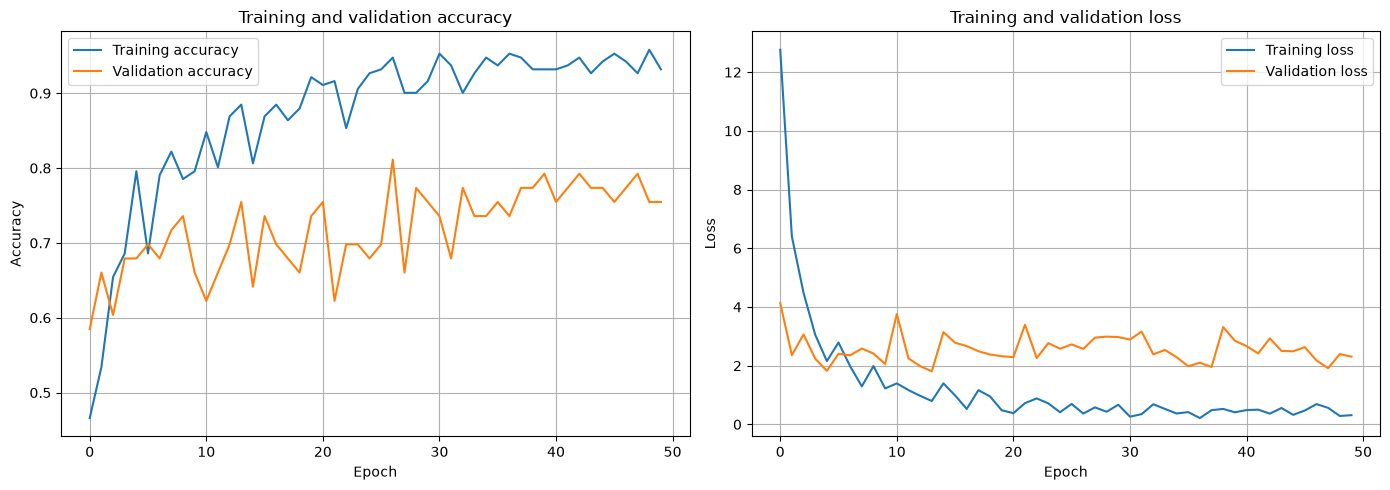

In [10]:
callbacks_02 = [
    keras.callbacks.ModelCheckpoint(
        filepath="./model3_checkpoints/02_fine_tuned_VGG16.keras",
        save_best_only=True,
        monitor="val_loss")
]

history_02 = model_02.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks_02,
    verbose=0
)

display_validation_results(history_02)
plot_training_history(history_02)

The best epoch was number 14. The validation accuracy was 0.7547, which is slightly higher than in the previous model (0.7358). The training accuracy was 0.8848. The training loss was 0.7967, and the validation loss was 1.8082.  

The training and validation accuracies are now closer to each other than in the previous model. Additionally, the difference between training and validation loss has decreased. These results suggest that overfitting has been reduced compared to the previous model. However, the validation loss is still higher than the training loss, indicating that some overfitting remains.

### Model 3

Next, we add `L2 regularization` (0.001) to the hidden layers of Model 2 to reduce overfitting. We also add early stopping, which stops the training if the validation loss does not improve for 10 epochs. Otherwise the model is the same as Model 2.

Best epoch: 3
Training accuracy: 0.5654
Validation accuracy: 0.8113
Training loss: 4.6458
Validation loss: 1.4836


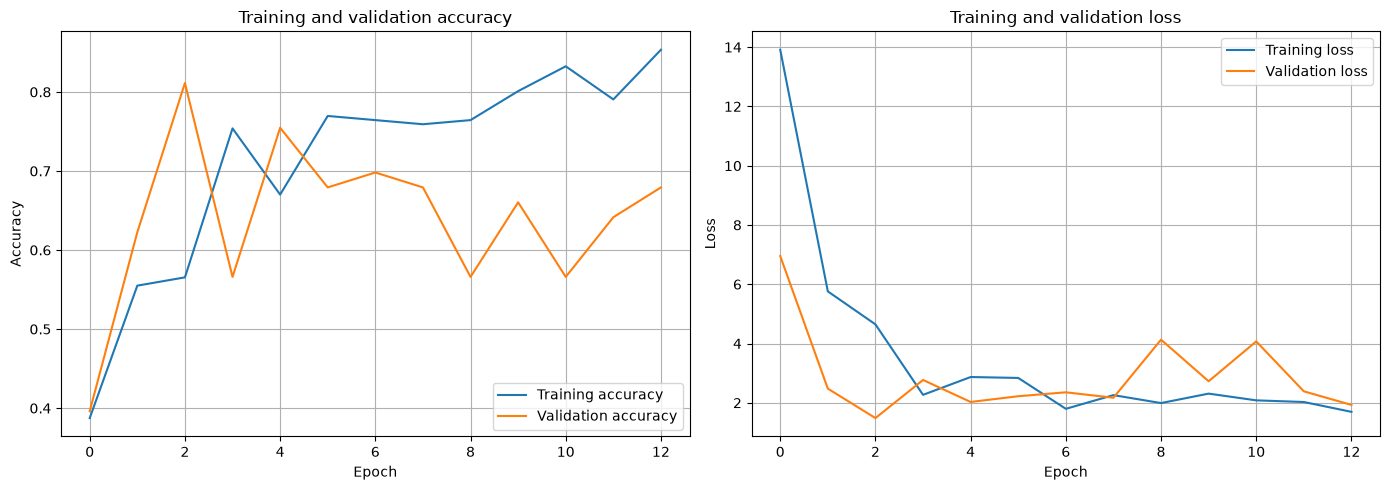

In [12]:
inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)

x = layers.Dense(256, activation="relu", kernel_regularizer=l2(0.001))(x)
x = layers.Dropout(0.5)(x)

x = layers.Dense(128, activation="relu", kernel_regularizer=l2(0.001))(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(3, activation="softmax")(x)

model_03 = keras.Model(inputs, outputs)

model_03.compile(loss="sparse_categorical_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

callbacks_03 = [
    keras.callbacks.ModelCheckpoint(
        filepath="./model3_checkpoints/03_fine_tuned_VGG16.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True)
]

history_03 = model_03.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks_03,
    verbose=0
)

display_validation_results(history_03)
plot_training_history(history_03)

The best epoch was number 3. The training accuracy was 0.5654, while the validation accuracy reached 0.8113. The training loss was 4.6458, while the validation loss was 1.4836.  

Compared to the previous model, the validation accuracy improved and the validation loss decreased. So the model performed better on the validation data.  

Interestingly, the validation accuracy was considerably higher than the training accuracy, and the validation loss was also lower than the training loss. This can partly be explained by data augmentation and dropout, which make training more challenging. Additionally, L2 regularization adds a penalty to the loss function, which can make it more difficult for the model to minimize the training loss.

### Model 4

Since the model 3 had the best validation accuracy of the previous models, let's try the same model but this time without early stopping.

Best epoch: 19
Training accuracy: 0.8586
Validation accuracy: 0.7547
Training loss: 1.6717
Validation loss: 2.5404


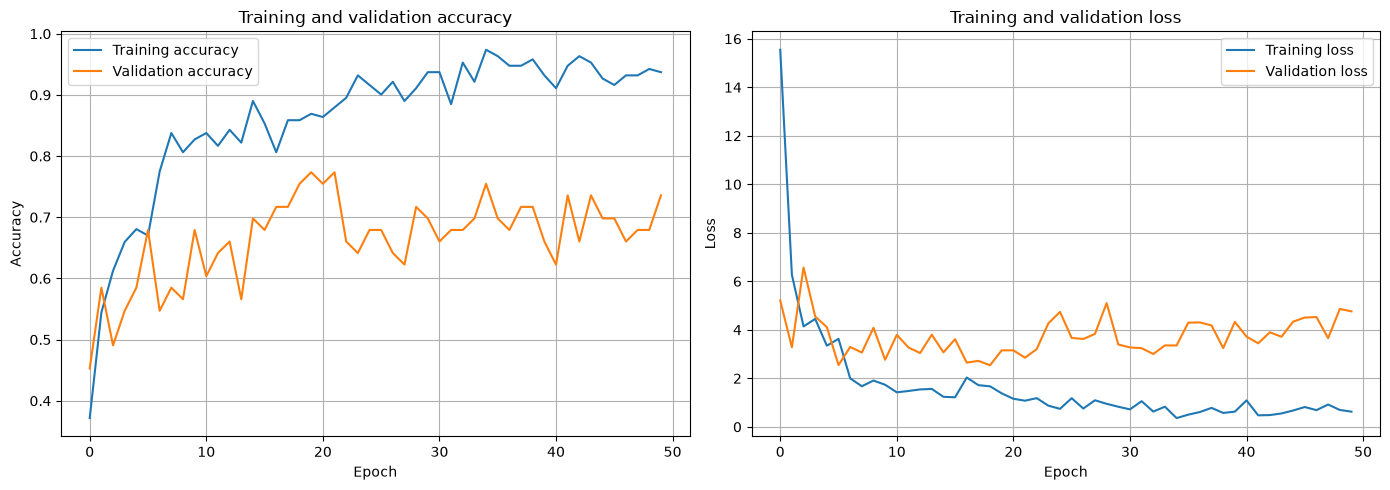

In [13]:
inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)

x = layers.Dense(256, activation="relu", kernel_regularizer=l2(0.001))(x)
x = layers.Dropout(0.5)(x)

x = layers.Dense(128, activation="relu", kernel_regularizer=l2(0.001))(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(3, activation="softmax")(x)

model_04 = keras.Model(inputs, outputs)

model_04.compile(loss="sparse_categorical_crossentropy",
              optimizer="rmsprop",
              metrics=["accuracy"])

callbacks_04 = [
    keras.callbacks.ModelCheckpoint(
        filepath="./model3_checkpoints/04_fine_tuned_VGG16.keras",
        save_best_only=True,
        monitor="val_loss")
]

history_04 = model_04.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks_04,
    verbose=0
)

display_validation_results(history_04)
plot_training_history(history_04)

The best epoch was number 19. The training accuracy was 0.8586, while the validation accuracy was 0.7547. The training loss was 1.6717, and the validation loss was 2.5404.

The training and validation accuracies are relatively close to each other. However, the validation loss is considerably higher than the training loss, and the graphs show that the validation loss increases and fluctuates during training. This indicates overfitting, even though the validation accuracy remains relatively stable.

Compared to model 3, removing early stopping allowed the model to train for longer and get higher training accuracy. The validation accuracy did not improve. So, longer training did not lead to better generalization.

### Fine-tuning the VGG16

Model 3 performed best from the previous models with a validation accuracy of 0.8113 and a validation loss of 1.4836. Therefore, we use it with the VGG16 model. The upper layers (last four layers) are unfrozen, and their training is fine-tuned with our model 3. That means, the weights in the upper layers are allowed to change.  

First, we download the best weights with model 3.

In [19]:
model3 = keras.models.load_model(
    "./model3_checkpoints/03_fine_tuned_VGG16.keras"
)

Then, we unfreeze the last four layers of the VGG16 model.

In [21]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False

# check the trainable status
for layer in conv_base.layers:
    print(f"{layer.name}: trainable={layer.trainable}")

input_layer: trainable=False
block1_conv1: trainable=False
block1_conv2: trainable=False
block1_pool: trainable=False
block2_conv1: trainable=False
block2_conv2: trainable=False
block2_pool: trainable=False
block3_conv1: trainable=False
block3_conv2: trainable=False
block3_conv3: trainable=False
block3_pool: trainable=False
block4_conv1: trainable=False
block4_conv2: trainable=False
block4_conv3: trainable=False
block4_pool: trainable=False
block5_conv1: trainable=True
block5_conv2: trainable=True
block5_conv3: trainable=True
block5_pool: trainable=True


Let's compile the model with a small learning rate.

In [23]:
model3.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.RMSprop(learning_rate=0.0001),
    metrics=["accuracy"],
)

model3.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 180, 180,  │          0 │ input_layer_5[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_9          │ (None, 180, 180)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_10         │ (None, 180, 180)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_11         │ (None, 180, 180)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_3 (Stack)     │ (None, 180, 180,  │          0 │ get_item_9[0][0], │
│                     │ 3)                │            │ get_item_10[0][0… │
│                     │                   │            │ get_item_11[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 180, 180,  │          0 │ stack_3[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 5, 5, 512) │ 14,714,688 │ add_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 12800)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 256)       │  3,277,056 │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 256)       │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 128)       │     32,896 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 128)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 3)         │        387 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,025,027 (68.76 MB)

 Trainable params: 3,310,339 (12.63 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Then, we fine-tune the model.

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 27s 4s/step - accuracy: 0.7016 - loss: 2.6978 - val_accuracy: 0.7547 - val_loss: 1.4516
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 22s 4s/step - accuracy: 0.7173 - loss: 2.5168 - val_accuracy: 0.7358 - val_loss: 1.4269
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 4s/step - accuracy: 0.7225 - loss: 2.6342 - val_accuracy: 0.7358 - val_loss: 1.4627
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 25s 4s/step - accuracy: 0.7120 - loss: 2.8763 - val_accuracy: 0.7358 - val_loss: 1.4966
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 22s 4s/step - accuracy: 0.6597 - loss: 3.2912 - val_accuracy: 0.6981 - val_loss: 1.6282
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 22s 4s/step - accuracy: 0.7906 - loss: 1.7819 - val_accuracy: 0.7358 - val_loss: 1.5903
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 4s/step - accuracy: 0.7801 - loss: 2.1890 - val_accuracy: 0.7170 - val_loss: 1.5912
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 4s/step - accuracy: 0.7382 - loss: 2.2014 - val_accuracy: 0.6792 - val_loss: 1.6745
Epoch 9/

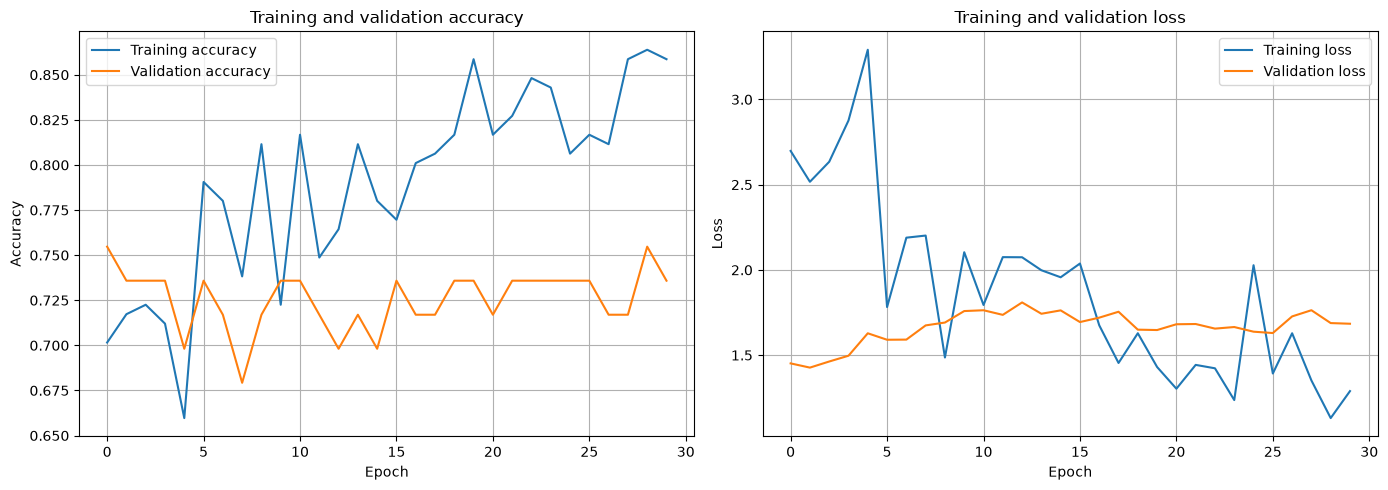

In [24]:
callbacks_finetune = [
    keras.callbacks.ModelCheckpoint(
        filepath="./model3_checkpoints/fine_tuned_VGG16_model3.keras",
        save_best_only=True,
        monitor="val_loss")
]

# train the model for 30 epochs
history_finetune = model3.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks_finetune,
)

# display results
display_validation_results(history_finetune)
plot_training_history(history_finetune)

The best validation loss value was achieved on epoch 2. The model achieved a training accuracy of 0.7173, while the validation accuracy was higher, 0.7358. Also, the validation loss (1.4269) was smaller than the training loss (2.5168).

<h2>5. Evaluation</h2>

The model is next evaluated with the test data. 

In [25]:
# load the final model
final_model = keras.models.load_model(
    "./model3_checkpoints/fine_tuned_VGG16_model3.keras"
)

# evaluate
test_loss, test_acc = final_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:4f}")
print(f"Test loss: {test_loss:4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.6981 - loss: 1.7368
Test accuracy: 0.698113
Test loss: 1.736810


With the test data, the model achieved an accuracy of 0.6981, which means it classified 69.81% of the images correctly. The test loss was 1.736810.  

Next, let's visualize some of the model's predictions.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 635ms/step


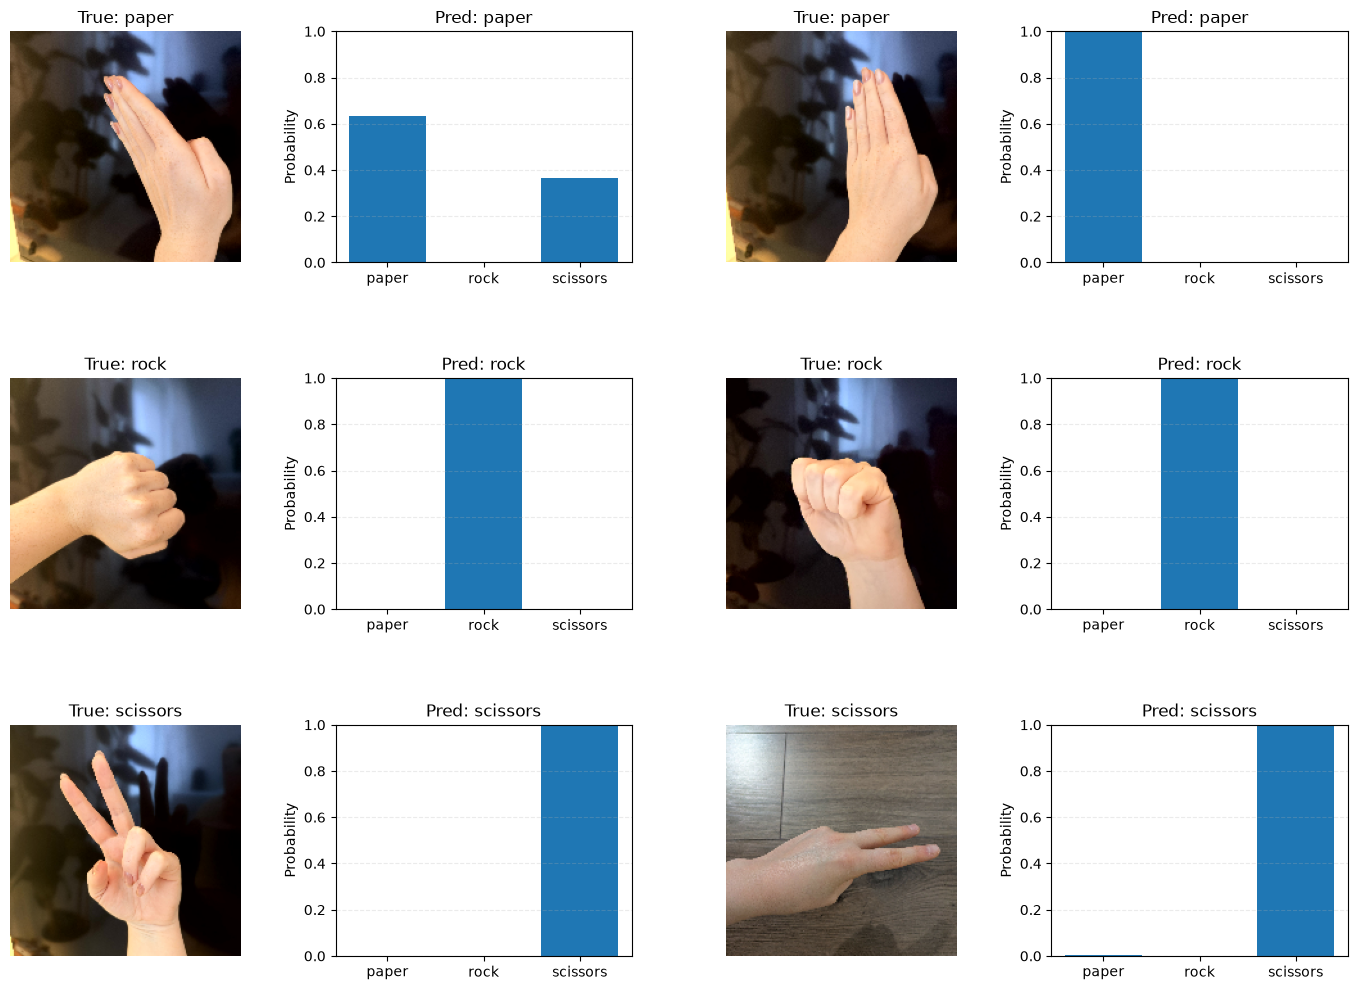

In [34]:
class_names = ["paper", "rock", "scissors"]

# collect all images and labels from the test dataset
all_images = []
all_labels = []

for images, labels in test_dataset:
    all_images.append(images.numpy())
    all_labels.append(labels.numpy())

all_images = np.concatenate(all_images, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

# pick 2 sample indices for each class (0: paper, 1: rock, 2: scissors)
indices = []
for target_class in range(3):
    class_indices = np.where(all_labels == target_class)[0]
    indices.extend(class_indices[-2:])  # Takes the last 2 images of each class

selected_images = all_images[indices]
selected_labels = all_labels[indices]

# make predictions using final_model
probs = final_model.predict(selected_images)

# plot 3 rows and 4 columns (row 1: paper, row 2: rock, row 3: scissors)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row in range(3):
    for col in range(2):
        idx = row * 2 + col
        true_label = int(selected_labels[idx])
        pred_label = np.argmax(probs[idx])

        # subplot for image
        img_ax = axes[row, col * 2]
        img = selected_images[idx]
        if img.max() > 1.0:
            img = img / 255.0

        img_ax.imshow(img)
        img_ax.set_title(f"True: {class_names[true_label]}")
        img_ax.axis("off")

        # subplot for probability
        bar_ax = axes[row, col * 2 + 1]
        bar_ax.bar(class_names, probs[idx])
        bar_ax.set_title(f"Pred: {class_names[pred_label]}")
        bar_ax.set_ylabel("Probability")
        bar_ax.set_ylim(0, 1)
        bar_ax.grid(axis="y", linestyle="--", alpha=0.25)
        bar_ax.tick_params(axis="x")

plt.tight_layout()
plt.subplots_adjust(hspace=0.5)
plt.show()

From the six images above, the model correctly identified all six. For five out of the six images, the model was really confident: it predicted a 100% propability for four images, and approximately 99% for one. However, the first image had a different distribution. The model gave a probability of around 62% to *paper* and around 38% to *scissors* class.  

Finally, let's plot the confusion matrix to see where the model predicts incorrectly.

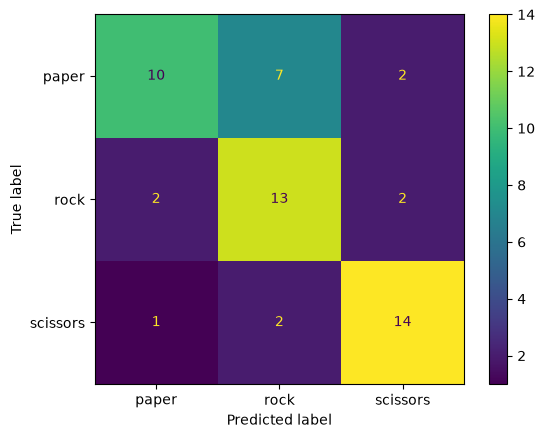

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# get true labels and predictions for the test dataset
y_true = np.concatenate([y.numpy() for _, y in test_dataset])
y_pred = np.argmax(final_model.predict(test_dataset, verbose=0), axis=1)

# plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
cmd = ConfusionMatrixDisplay(cm, display_labels=class_names)
cmd.plot()

The model made the most misclassifications in the *paper* class: 7 out of 19 images were misclassified as *rock*. Additionally, it misclassified 2 *paper* images as *scissors*, 2 *rock* images as *paper* and 2 as *scissors*. From the *scissors* class it misclassified 1 image as *paper* and 2 images as *rock*.  

The correct classifications per class are the following: *paper* 10, *rock* 13 and *scissors* 14. The test set contains 19 *paper* images, 17 *rock* images and 17 *scissors* images.

<h2>6. Deployment</h2>

The model achieved a test accuracy of approximately 69.8%, so it classifies about 7 out of 10 images correctly. It recognized *rock* and *scissors* better than *paper*, which was most often mistaken for *rock*.

The small dataset, with 297 images in total, most likely limits the model's performance. At the moment, the model is suitable only as a prototype. Before real-world use, it should be improved by adding more training images, especially of *paper*. The improved model should then be tested with new images taken in different lighting conditions and backgrounds.